# 20. Compatible element recovery beyond one pass

The wire failure occurs on straight as well as curved tetrahedra. Revisiting shared degrees of freedom restores compatible curls at p > 1. This notebook reads saved native evidence; it does not require NGSolve to display the results.

See the [derivation, source comparison and reproduction commands](COMPATIBLE_ELEMENT_RECOVERY.md), [previous full CLN control](19_element_cln_integration.ipynb) and [A-T accuracy ranking](17_formulation_ranking.ipynb).

The verified primary source is [Bíró and Köster, Compumag 2021, Section IV](https://www.compumag.org/Proceedings/2021_Cancun/www.conftool.pro/compumag2021/index.php/OA1-2-299ecbe.pdf?filename=OA1-2-299.pdf&form_id=299&form_version=final&ismobile=false&page=downloadPaper). The cited 2021 Bíró/Gyimesi journal full text was unavailable; no unverified one-pass theorem is attributed to it.

**Follow-up:** [Notebook 21](21_scalar_potential_cln.ipynb) replaces the remaining global physical A-T vector solves with compatible V/Phi scalar Poisson steps. The results below retain the earlier recovery-only integration.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
root = Path.cwd()
if root.name == 'docs': root = root.parent
study = json.loads((root/'docs/data/compatible_recovery_study.json').read_text())
diag = json.loads((root/'docs/data/curl_sweep_diagnosis.json').read_text())
assert study['complete'] and diag['complete']
print('Native runtime:', study['runtime'])
print(study['timing_protocol'])

Native runtime: {'host': 'intel11', 'python': '3.12.10', 'ngsolve': '6.2.2607', 'numpy': '2.5.2', 'radia': '5.2.3', 'threads': 4}
First observed plus three warmed complete runs; alternating routes; mesh and cross-comparison excluded; assembly, setup, recovery and checks included


## Cause, with geometry and equation controls

The source's local equation is $K_e t_e=f_e$. The archived prototype used its square-root constraint $C_e t_e=y_e$, where $K_e=C_e^T C_e$. Both produce the same feasible set, but their least-squares residual weights differ if previously frozen coefficients make that set empty. The controls below retain both choices, forward/reverse/shuffled traversal and the same element connectivity for geometry orders 1 and 3.

Freezing all visited shared coefficients makes later local constraints unextendable. This happens already at p=1 and on straight elements. A successful small cube in notebook 18 was insufficient to justify a general one-pass claim.

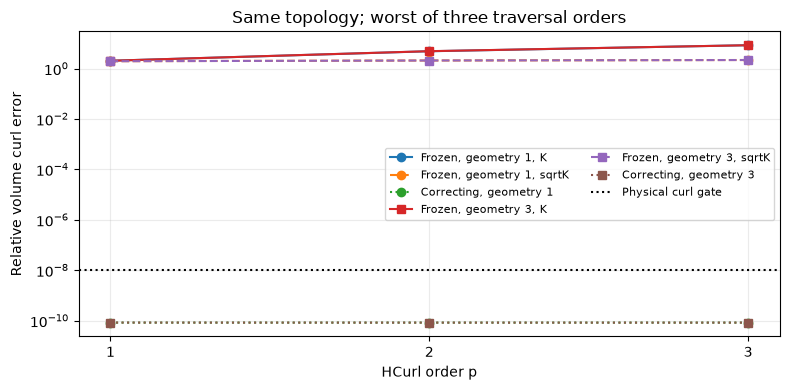

geometry 1 p 1 first frozen conflict: {'visited': 56, 'element': 56, 'unknown_dofs': 0, 'local_dofs': 12, 'relative_local_curl_error': 2.4431595710148635}
geometry 1 p 2 first frozen conflict: {'visited': 56, 'element': 56, 'unknown_dofs': 6, 'local_dofs': 30, 'relative_local_curl_error': 2.852707367748464}
geometry 1 p 3 first frozen conflict: {'visited': 56, 'element': 56, 'unknown_dofs': 20, 'local_dofs': 60, 'relative_local_curl_error': 3.134944237889134}
geometry 3 p 1 first frozen conflict: {'visited': 56, 'element': 56, 'unknown_dofs': 0, 'local_dofs': 12, 'relative_local_curl_error': 2.449828164557382}
geometry 3 p 2 first frozen conflict: {'visited': 56, 'element': 56, 'unknown_dofs': 6, 'local_dofs': 30, 'relative_local_curl_error': 2.856125709854981}
geometry 3 p 3 first frozen conflict: {'visited': 56, 'element': 56, 'unknown_dofs': 20, 'local_dofs': 60, 'relative_local_curl_error': 3.1389554197230956}


In [2]:
assert len({c['topology_sha256'] for c in diag['cases']}) == 1
fig, ax = plt.subplots(figsize=(8,4))
for curve, marker in [(1,'o'),(3,'s')]:
    cases = [c for c in diag['cases'] if c['curve']==curve]
    for eq, style in [('K','-'),('sqrtK','--')]:
        ax.semilogy([c['order'] for c in cases], [max(r['relative_curl_field_error'] for r in c['greedy'] if r['equation']==eq) for c in cases], marker+style, label=f'Frozen, geometry {curve}, {eq}')
    ax.semilogy([c['order'] for c in cases], [max(r['relative_curl_field_error'] for r in c['iterative']) for c in cases], marker+':', label=f'Correcting, geometry {curve}')
ax.axhline(1e-8,color='k',ls=':',label='Physical curl gate')
ax.set(xlabel='HCurl order p',ylabel='Relative volume curl error',xticks=[1,2,3],title='Same topology; worst of three traversal orders')
ax.legend(fontsize=8,ncol=2);ax.grid(True,which='both',alpha=.25)
fig.tight_layout();plt.show()
for c in diag['cases']:
    r=next(x for x in c['greedy'] if x['sequence']=='forward' and x['equation']=='K')
    print('geometry',c['curve'],'p',c['order'],'first frozen conflict:',r['first_conflict'])

## Conforming local correction

For each element, apply $t[F_e] \leftarrow t[F_e]+C_{e,F}^{+}(y_e-C_eR_et)$. Essential boundary coefficients stay fixed. Shared free coefficients may change at every visit; one global NGSolve HCurl coefficient vector preserves tangential conformity, including high-order face and interior modes.

Each small SVD solve is a projection onto a local affine constraint set. Cyclic projections converge in exact arithmetic when the constraints have a common solution. No global recovery matrix is assembled. This is a multiple-sweep method, with no linear-complexity claim. The tolerance is 1e-10 for the all-element fit, 1e-8 for integrated physical curl error, and 1e-6 for the recovered original physical equation. One-sweep caps and nonzero-divergence target fields must reject. A preliminary curved p=1 trial stalled near 1.17e-11 at a tighter requested fit; failed operational evidence is retained outside Git.

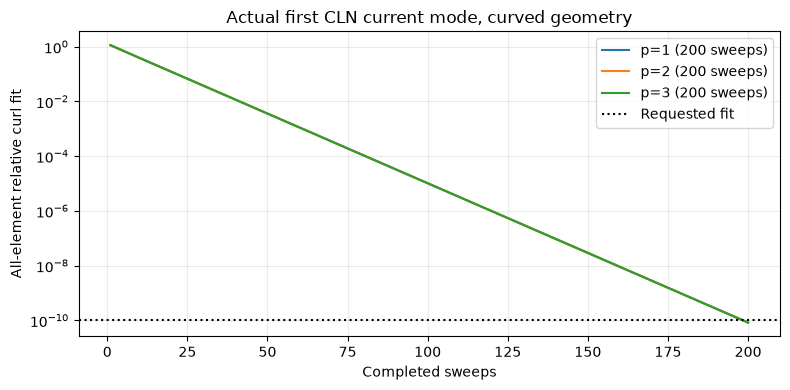

All six capped controls rejected: True
All six incompatible-field controls rejected: True


In [3]:
fig,ax=plt.subplots(figsize=(8,4))
for c in diag['cases']:
    if c['curve']!=3:continue
    for r in c['iterative']:
        if r['sequence']!='forward':continue
        history=np.asarray(r['history'])
        ax.semilogy(history[:,0],history[:,1],label=f"p={c['order']} ({r['sweeps']} sweeps)")
ax.axhline(1e-10,color='k',ls=':',label='Requested fit')
ax.set(xlabel='Completed sweeps',ylabel='All-element relative curl fit',title='Actual first CLN current mode, curved geometry')
ax.legend();ax.grid(True,which='both',alpha=.25);fig.tight_layout();plt.show()
print('All six capped controls rejected:',all(not c['capped_failure']['converged'] for c in diag['cases']))
print('All six incompatible-field controls rejected:',all('incompatible_failure' in c for c in diag['cases']))

## Full CLN: seven coefficients, seven modes, seven solves

Each recovered field feeds the next stage of the unchanged A-T recursion. The same mesh, spaces, quadrature, normalization and zero expansion point are used for original ICCG, condensed A-T and condensed A-T followed by iterative element recovery. Volume comparisons use the norm of the vector difference; saved energy and 78-point vector samples add portable checks. Potential coefficients are not compared because the gradient gauge is immaterial to the physical fields.

The global physical trace solve remains present. This is not yet the full Bíró scalar V/Phi replacement of global vector solves. Passing this test establishes representation and recursion parity on these wire cases, not new continuum accuracy or superiority over all formulations.

In [4]:
print('p  h[mm]  max coefficient diff   max volume field diff   max recovered equation residual')
for c in study['cohorts']:
    comp=[r for r in c['comparisons'] if r['route']=='compatible-sweep']
    runs=[r for r in c['repeats'] if r['route']=='compatible-sweep']
    ce=max(abs(x) for r in comp for x in r['relative_coefficients'])
    fe=max(x for r in comp for x in r['volume_relative_field_errors'])
    re=max(s['recovered_original_residual'] for r in runs for s in r['solves'])
    print(c['order'],c['maxh']*1000,f'{ce:.3e}',f'{fe:.3e}',f'{re:.3e}')
print('Completed full runs:',sum(len(c['repeats']) for c in study['cohorts']))
print('Accepted local recoveries:',sum(len(r['solves']) for c in study['cohorts'] for r in c['repeats'] if r['route']=='compatible-sweep'))

p  h[mm]  max coefficient diff   max volume field diff   max recovered equation residual
2 3.0 1.031e-10 1.054e-08 3.846e-10
3 3.0 1.032e-10 9.867e-09 3.846e-10
3 2.0 7.320e-11 1.286e-09 4.256e-10
4 3.0 1.054e-10 9.591e-09 3.847e-10
Completed full runs: 48
Accepted local recoveries: 112


original warmed median seconds: [np.float64(0.8358), np.float64(2.0224), np.float64(6.071), np.float64(5.9437)]
condensed warmed median seconds: [np.float64(0.6648), np.float64(1.5509), np.float64(4.6477), np.float64(3.3023)]
compatible-sweep warmed median seconds: [np.float64(5.19), np.float64(9.2055), np.float64(37.4858), np.float64(18.6349)]


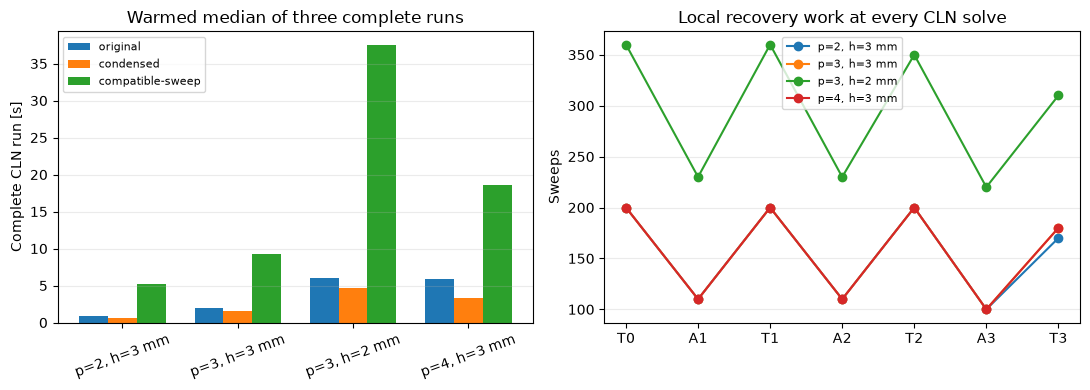

In [5]:
routes=['original','condensed','compatible-sweep']
fig,axes=plt.subplots(1,2,figsize=(11,4))
x=np.arange(len(study['cohorts']))
labels=[f"p={c['order']}, h={c['maxh']*1000:g} mm" for c in study['cohorts']]
for j,route in enumerate(routes):
    median=[np.median([r['seconds'] for r in c['repeats'] if r['route']==route and r['repeat']>0]) for c in study['cohorts']]
    axes[0].bar(x+(j-1)*.25,median,.25,label=route)
    print(route,'warmed median seconds:',[round(v,4) for v in median])
for c in study['cohorts']:
    r=next(r for r in c['repeats'] if r['route']=='compatible-sweep' and r['repeat']==0)
    axes[1].plot(range(7),[s['sweeps'] for s in r['solves']],'-o',label=f"p={c['order']}, h={c['maxh']*1000:g} mm")
axes[0].set(xticks=x,xticklabels=labels,ylabel='Complete CLN run [s]',title='Warmed median of three complete runs')
axes[0].tick_params(axis='x',rotation=20);axes[0].legend(fontsize=8)
axes[1].set(xticks=range(7),xticklabels=['T0','A1','T1','A2','T2','A3','T3'],ylabel='Sweeps',title='Local recovery work at every CLN solve')
axes[1].legend(fontsize=8)
for ax in axes:ax.grid(True,axis='y',alpha=.25)
fig.tight_layout();plt.show()

The iterative recovery adds substantial work to the retained physical solve. Its benefit here is compatible high-order field reconstruction using element matrices, not measured acceleration. An efficient full scalar-potential formulation remains a separate implementation task. Multiply connected geometries, air/material interfaces and positive shifts have not been established by this experiment.

The [portable evidence gate](../validation/validate_compatible_recovery.py) checks source identities, coverage, energies, vector samples, all physical equation residuals and convergence. Eight deliberate data corruptions must fail. This addition is Codex self-review; it does not claim a new independent scientific review. Existing A-T accuracy findings remain in notebook 17.